# Experiment 0A: are extraction inputs and runtimes ready?

This is an evidence inventory, not a new test run. A dated receipt is distinct from current-source approval, and a small passing pilot is distinct from complete feature creation.

| Figure | Shows |
|---|---|
| 1 · Runtime evidence | for each extractor and encoder: pinned configuration, staged receipt, full-bank token counts, bounded API/GPU contract and review status available locally |
| 2 · Cached decision outputs | decoded lifetime responses, with historical versions kept distinct in the table |

Figure 2 is a descriptive cache inventory. It may mix historical question and runtime versions, so its spread cannot isolate differences between texts or establish a provider comparison.

## 1. Scope and provenance

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import matplotlib.pyplot as plt
from src.utils.notebook_display import display_local, display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.utils.provenance import provenance
from src.visualize import figures, style
style.apply()
NOTEBOOK = '3. experiment_0/01_before_feature_creation'
begin_report()
save = figures.FigureSaver(NOTEBOOK)
report_section("1. Scope, provenance and saved evidence")
display_json("Notebook execution identity", provenance())


## 2. Runtime evidence

Read the evidence by model and stage. Unknown means unavailable locally, not failure.

model_id,model,pin,configured,staged_receipt,full_bank_tokens,bounded_runtime,semantic_review,complete_feature_datasets,observed_utc,source,source_sha256,staged_manifest
jev,jev-1.13.0,1.13.0,observed,not_applicable,not_applicable,unknown,unknown,not assessed here,not found locally,None,None,None
liquid,LiquidAI/d1-3B,051bcc464b01b9f92942b364d9586b0ef5912432,observed,unknown,unknown,unknown,unknown,not assessed here,not found locally,None,None,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\liquid\_JEVPFN_CHECKPOINT.json
liquid_lfm3,LiquidAI/d1-2B,cfe5760ff5d5998f91d9ac56bd4b2dbd96996d41,observed,unknown,unknown,unknown,unknown,not assessed here,not found locally,None,None,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\liquid_lfm3\_JEVPFN_CHECKPOINT.json
perplexity,perplexity-ai/pplx-decider-v1.1-27b,14c9d90137962d300f3de95633f7b6535e80c5ce,observed,unknown,unknown,unknown,unknown,not assessed here,not found locally,None,None,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\perplexity\_JEVPFN_CHECKPOINT.json
cloudflare,Cloudflare/clef-flash,8b2e5fd17c09fd49bc2880b805d5323ec7ff4ff3,observed,unknown,unknown,unknown,unknown,not assessed here,not found locally,None,None,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\cloudflare\_JEVPFN_CHECKPOINT.json
intern,internlm/Intern-Decision-4B,0e5e6aa7d6d750e2b1504ba11a8136cb58aeb3cd,observed,unknown,unknown,unknown,unknown,not assessed here,not found locally,None,None,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\intern\_JEVPFN_CHECKPOINT.json
strands,StrandsAgents/strands-decider-2B-qwen3.5-v1-2610,216d1ccb46a9e9b036eb9187b248db98480f77d4,observed,unknown,unknown,unknown,unknown,not assessed here,not found locally,None,None,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\strands\_JEVPFN_CHECKPOINT.json
h2o,h2oai/h2o-lightning-4b,e7b32490c9d2a994bd75a4d1ea7e45716080175e,observed,unknown,unknown,unknown,unknown,not assessed here,not found locally,None,None,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\h2o\_JEVPFN_CHECKPOINT.json
sii,jylin001206/SII-Decision-27B-Full,8f5a51dcde7b0fd6a2eea3ab423bad5e3b11dfda,observed,unknown,unknown,unknown,unknown,not assessed here,not found locally,None,None,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\sii\_JEVPFN_CHECKPOINT.json
kev,jaredpalmer/kev-27b,af0e6d551bdc2cc724f3e9d7a8bee1cd4fb8f7bf,observed,unknown,unknown,unknown,unknown,not assessed here,not found locally,None,None,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\kev\_JEVPFN_CHECKPOINT.json


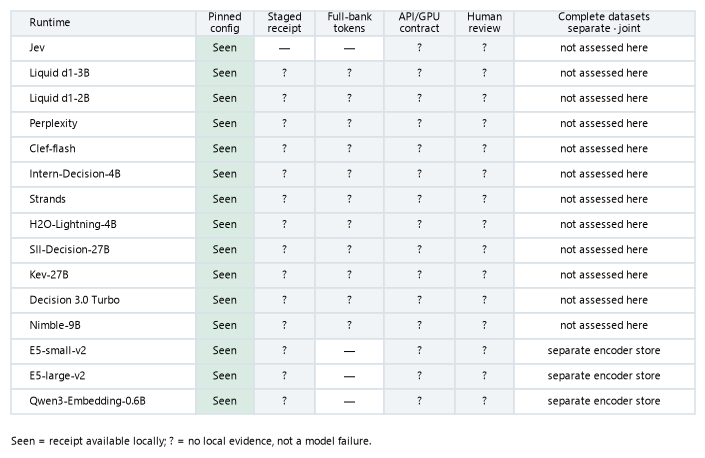

In [2]:
report_section('2. Runtime evidence')
from src.evaluation.notebook_evidence import local_runtime_evidence
from src.visualize.research import runtime_evidence_figure
evidence, token_scope = local_runtime_evidence()
display_table("Runtime pins, receipt provenance and recorded status", evidence, preview_rows=14)
display_json("Exact token audit scope", token_scope)
for fig, name, caption in [runtime_evidence_figure(evidence)]:
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)


## 3. What do the cached decision features look like?

Every verified response in the local response caches is decoded with the production decoder: binary positive-class probabilities, multiclass normalized entropy, and regression expected direction. This reads all cached verified responses, including historical settings and any later production entries; it does not certify pilot membership or current-source acceptance. No target values are read. Invalid responses are counted and excluded.

provider,settings_sha256,task_type,count,mean,std,min,25%,50%,75%,max
cloudflare,bed142d79dc860c39a253ef292ba49df4c19182c191b0a30943b0926a1d3c7c4,binary_classification,6.0,0.193,0.169,0.018,0.079,0.147,0.282,0.466
cloudflare,bed142d79dc860c39a253ef292ba49df4c19182c191b0a30943b0926a1d3c7c4,multiclass_classification,12.0,0.612,0.217,0.308,0.430,0.673,0.778,0.874
cloudflare,bed142d79dc860c39a253ef292ba49df4c19182c191b0a30943b0926a1d3c7c4,regression,18.0,-0.185,0.615,-1.328,-0.506,-0.067,0.032,1.153
intern,59ca52a17cf6c3c19cc92b7bb70d1e199536a9fe0fd27df8e7d839ab6ed043ed,binary_classification,6.0,0.164,0.126,0.059,0.070,0.117,0.222,0.377
intern,59ca52a17cf6c3c19cc92b7bb70d1e199536a9fe0fd27df8e7d839ab6ed043ed,multiclass_classification,12.0,0.529,0.209,0.120,0.488,0.533,0.706,0.758
intern,59ca52a17cf6c3c19cc92b7bb70d1e199536a9fe0fd27df8e7d839ab6ed043ed,regression,18.0,-0.149,0.387,-1.395,-0.076,-0.050,-0.039,0.491
jev,de213f0faeb23629b483bdf36403c2a644e1da935a83072927e4b1c540b034f1,binary_classification,27.0,0.234,0.106,0.040,0.165,0.260,0.300,0.420
jev,de213f0faeb23629b483bdf36403c2a644e1da935a83072927e4b1c540b034f1,multiclass_classification,87.0,0.508,0.300,-0.000,0.298,0.508,0.792,0.986
provider,settings_sha256,task_type,count,mean,std,min,25%,50%,75%,max
cloudflare,bed142d79dc860c39a253ef292ba49df4c19182c191b0a30943b0926a1d3c7c4,binary_classification,6.0,0.193,0.169,0.018,0.079,0.147,0.282,0.466


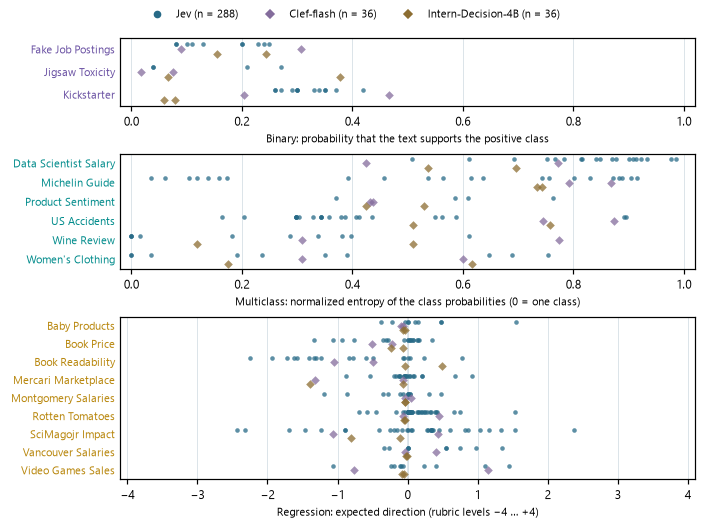

In [3]:
report_section('3. Cached decision features')
from src.evaluation.notebook_evidence import pilot_decision_outputs
from src.visualize.research import pilot_output_figures
pilot = pilot_decision_outputs()
display_table("Cached responses by provider, settings and task", pilot.groupby(["provider", "settings_sha256", "task_type"]).value.describe().round(3).reset_index())
record({"invalid_responses": pilot.attrs.get("invalid_responses", 0), "responses": len(pilot)}, "Decoded lifetime cached responses")
for fig, name, caption in pilot_output_figures(pilot):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)

## 4. What each test establishes

CPU tests check input construction, storage/recovery and exact tokenization. GPU/API contracts check actual response semantics and bounded real-text requests. Neither proves full-dataset predictor feasibility.

In [4]:
report_section('4. What each test establishes')
from src.utils.config import load_yaml
display_json("Configured extraction acceptance gates", load_yaml("experiment_0/debug"))
record("Before extraction: review exact token/window coverage, semantic anchors, sensitivity diagnostics, recoverability, spending/rate limits, storage protection and current source/runtime identities. Exp4 examines sensitivity; 0B checks full features and predictors.", "Interpretation")

## Complete printed report

Everything displayed above is printed in section order. Individual predictions and the full metric store remain available in the referenced evaluation databases.

In [5]:
finish_report(NOTEBOOK, save.summary() + "\nNo fitting, inference or outcome-based method selection was performed.")

3. experiment_0/01_before_feature_creation

1. Scope, provenance and saved evidence


Notebook execution identity
{
  "code_sha256": "f42a9b73a320a8f93eb96ab679e299ccf311d70806bb59c27599e57eb5256e9f",
  "git_head": "a22a785beae217626e6732b0458c653f33420a1f",
  "git_dirty": true,
  "tfm_library_pin": "8be0408ef0f6debf7f5d852a49380186d832f1a9 dm-library (remotes/origin/HEAD)\n 26156f36eb7676e8d9050547817346db548b0e85 tfm-library (remotes/origin/HEAD)\n 0ed4ffa89d312b9bb6411681b6a14f81672439f3 vsc-library (remotes/origin/HEAD)",
  "environment": {
    "python": "3.12.10",
    "numpy": "2.5.3",
    "pandas": "2.3.3",
    "PyYAML": "6.0.3",
    "matplotlib": "3.11.2",
    "pyarrow": "25.0.1"
  }
}


2. Runtime evidence


Runtime pins, receipt provenance and recorded status
            model_id                                            model                                      pin configured staged_receipt full_bank_tokens bounded_runtime semantic_review complete_feature_datasets      obse